# Fare-Free Bus Routes in Boston: Analysis

This notebook compares Boston's fare-free bus routes (**23, 28 and 29**) with **Route 22**, which serves the same neighborhoods but still charges a fare.

- Route 28 became fare-free in **August 2021**
- Routes 23 and 29 became fare-free in **March 2022**

All data comes from the cleaned files in `data/processed`.

## 0. Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

processed = r'C:\Users\sahil\projects\boston-mbta-ridership\data\processed'
figures   = r'C:\Users\sahil\projects\boston-mbta-ridership\figures\final'

# Pastel color for each route, same in every chart
colors = {'23': '#F6A96B', '28': '#E87A90', '29': '#B39CD0', '22': '#7FB3D5'}

# Load ridership, weekdays only
route_year = pd.read_csv(processed + r'\ridership_route_year.csv', dtype={'route_id': str})
weekday = route_year[route_year['day_type'] == 'weekday']

## 1. Ridership: Focus Routes

How did ridership change on the three fare-free routes compared with Route 22?
All charts use **weekday** ridership from the Fall of each year, unless stated otherwise.

### B1. Weekday riders, 2016–2025

Average weekday boardings on each route, Fall 2016 to Fall 2025.
The grey band marks 2020 (COVID), and the dotted lines mark when each route became fare-free.

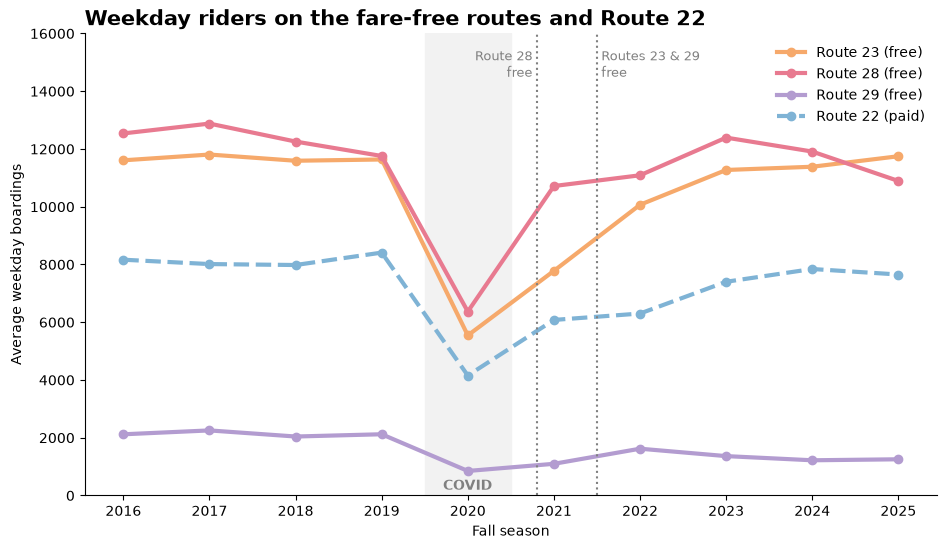

In [2]:
fig, ax = plt.subplots(figsize=(11, 6))

r23 = weekday[weekday['route_id'] == '23'].sort_values('year')
r28 = weekday[weekday['route_id'] == '28'].sort_values('year')
r29 = weekday[weekday['route_id'] == '29'].sort_values('year')
r22 = weekday[weekday['route_id'] == '22'].sort_values('year')


ax.plot(r23['year'], r23['avg_daily_boardings'], color=colors['23'], linewidth=3, marker='o', label='Route 23 (free)')
ax.plot(r28['year'], r28['avg_daily_boardings'], color=colors['28'], linewidth=3, marker='o', label='Route 28 (free)')
ax.plot(r29['year'], r29['avg_daily_boardings'], color=colors['29'], linewidth=3, marker='o', label='Route 29 (free)')
ax.plot(r22['year'], r22['avg_daily_boardings'], color=colors['22'], linewidth=3, marker='o', linestyle='--', label='Route 22 (paid)')

# COVID year
ax.axvspan(2019.5, 2020.5, color='#F2F2F2')
ax.text(2020, 200, 'COVID', ha='center', fontsize=10, color='gray', fontweight='bold')

# Fare-free start dates
ax.axvline(2020.8, color='gray', linestyle=':')
ax.axvline(2021.5, color='gray', linestyle=':')
ax.text(2020.75, 14500, 'Route 28\nfree', ha='right', fontsize=9, color='gray')
ax.text(2021.55, 14500, 'Routes 23 & 29\nfree', fontsize=9, color='gray')


ax.set_title('Weekday riders on the fare-free routes and Route 22', fontsize=15, fontweight='bold', loc='left')
ax.set_xlabel('Fall season')
ax.set_ylabel('Average weekday boardings')
ax.set_xticks(range(2016, 2026))
ax.set_ylim(0, 16000)
ax.legend(frameon=False)
ax.spines[['top', 'right']].set_visible(False)


plt.show()

**Takeaway:** All four routes collapsed in 2020. Route 28 rebounded sharply in its first fare-free fall (2021), and Route 23 climbed back to its pre-COVID level after becoming free in 2022. Route 22, which kept its fare, is still below its 2019 ridership. Route 29 stayed low, reflecting service cuts rather than the fare change.

### B2. Change in weekday riders since 2019

Each route's ridership as a percentage change from its own Fall 2019 level, so routes of different sizes can be compared directly.
A value of 0% means the route is back to its 2019 ridership.

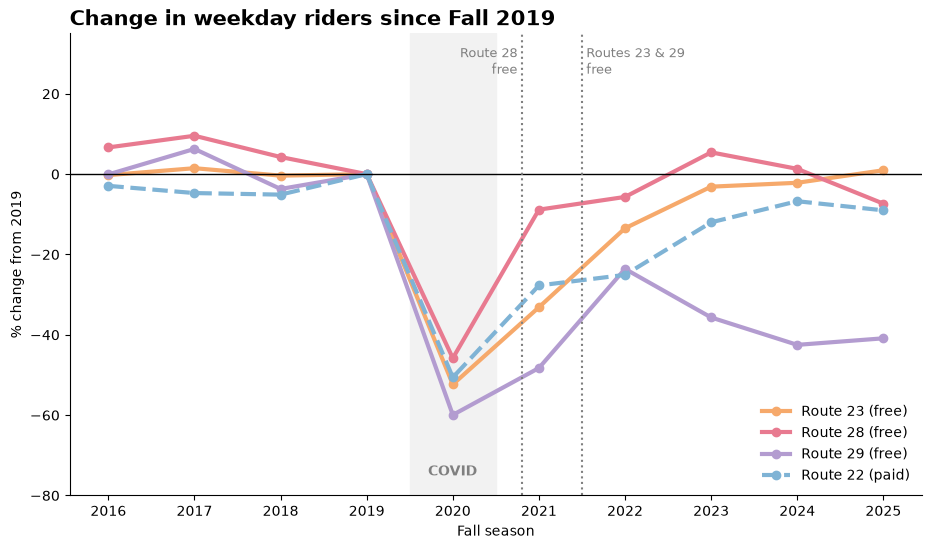

In [3]:
# Each route's 2019 ridership is its starting point
r23['pct_change'] = (r23['avg_daily_boardings'] / r23[r23['year'] == 2019]['avg_daily_boardings'].values[0] - 1) * 100
r28['pct_change'] = (r28['avg_daily_boardings'] / r28[r28['year'] == 2019]['avg_daily_boardings'].values[0] - 1) * 100
r29['pct_change'] = (r29['avg_daily_boardings'] / r29[r29['year'] == 2019]['avg_daily_boardings'].values[0] - 1) * 100
r22['pct_change'] = (r22['avg_daily_boardings'] / r22[r22['year'] == 2019]['avg_daily_boardings'].values[0] - 1) * 100

fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(r23['year'], r23['pct_change'], color=colors['23'], linewidth=3, marker='o', label='Route 23 (free)')
ax.plot(r28['year'], r28['pct_change'], color=colors['28'], linewidth=3, marker='o', label='Route 28 (free)')
ax.plot(r29['year'], r29['pct_change'], color=colors['29'], linewidth=3, marker='o', label='Route 29 (free)')
ax.plot(r22['year'], r22['pct_change'], color=colors['22'], linewidth=3, marker='o', linestyle='--', label='Route 22 (paid)')

# 2019 level
ax.axhline(0, color='black', linewidth=1)

# COVID year
ax.axvspan(2019.5, 2020.5, color='#F2F2F2')
ax.text(2020, -75, 'COVID', ha='center', fontsize=10, color='gray', fontweight='bold')

# Fare-free start dates
ax.axvline(2020.8, color='gray', linestyle=':')
ax.axvline(2021.5, color='gray', linestyle=':')
ax.text(2020.75, 25, 'Route 28\nfree', ha='right', fontsize=9, color='gray')
ax.text(2021.55, 25, 'Routes 23 & 29\nfree', fontsize=9, color='gray')

# Labels
ax.set_title('Change in weekday riders since Fall 2019', fontsize=15, fontweight='bold', loc='left')
ax.set_xlabel('Fall season')
ax.set_ylabel('% change from 2019')
ax.set_xticks(range(2016, 2026))
ax.set_ylim(-80, 35)
ax.legend(frameon=False, loc='lower right')
ax.spines[['top', 'right']].set_visible(False)

plt.show()

**Takeaway:** Measured against its own 2019 level, Route 23 is back above pre-COVID ridership (+1%), Route 28 is 7% below, and Route 22 (paid) is 9% below. Route 29 remains 41% below 2019.

### B3. Did ridership follow service?

Left: change in **service** (weekday trips), January–February 2020 to January–February 2025.
Right: change in **riders** (weekday boardings), Fall 2019 to Fall 2025.
Both panels use the same scale. If a route's rider bar is smaller than its service bar, riders held on even as service was cut.

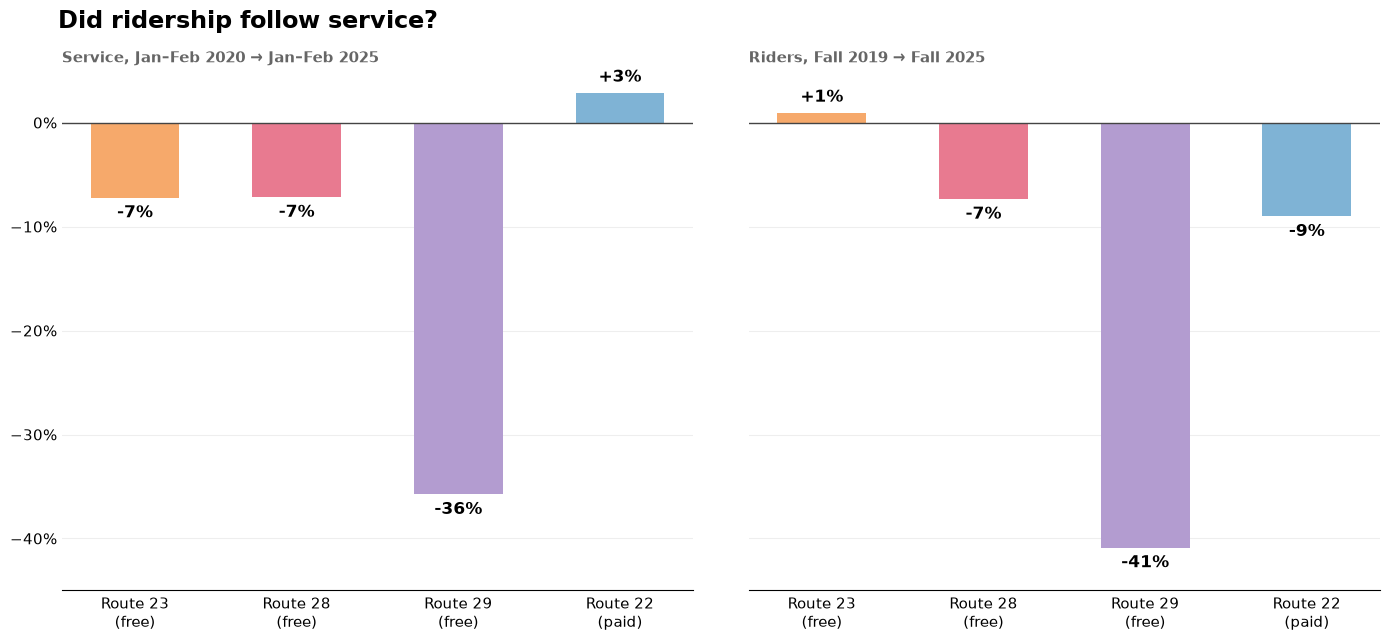

In [4]:
import matplotlib.ticker as mticker
#Service: weekday trips, Jan-Feb 2020 vs. Jan-Feb 2025
service = pd.read_csv(processed + r'\service_route_month.csv', dtype={'route_id': str})
winter = service[(service['day_type'] == 'weekday') & (service['month'].isin([1, 2]))]

trips_2020 = winter[winter['year'] == 2020].groupby('route_id')['n_trips'].sum()
trips_2025 = winter[winter['year'] == 2025].groupby('route_id')['n_trips'].sum()
trip_change = (trips_2025 / trips_2020 - 1) * 100

#Riders: Fall 2019 vs. Fall 2025
riders = weekday.pivot(index='year', columns='route_id', values='avg_daily_boardings')
rider_change = (riders.loc[2025] / riders.loc[2019] - 1) * 100

#Four routes, same order in both panels 
routes = ['23', '28', '29', '22']
names  = ['Route 23\n(free)', 'Route 28\n(free)', 'Route 29\n(free)', 'Route 22\n(paid)']
bar_colors = [colors['23'], colors['28'], colors['29'], colors['22']]

service_values = trip_change[routes]
rider_values   = rider_change[routes]

#Two panels, same y-axisimport matplotlib.ticker as mticker

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6.5), sharey=True)

#Left: service
bars1 = ax1.bar(names, service_values, color=bar_colors, width=0.55)
ax1.bar_label(bars1, labels=[f'{v:+.0f}%' for v in service_values], padding=5, fontsize=12, fontweight='bold')
ax1.set_title('Service, Jan–Feb 2020 → Jan–Feb 2025', fontsize=11, fontweight='bold', color='#666666', loc='left')

#Right: riders
bars2 = ax2.bar(names, rider_values, color=bar_colors, width=0.55)
ax2.bar_label(bars2, labels=[f'{v:+.0f}%' for v in rider_values], padding=5, fontsize=12, fontweight='bold')
ax2.set_title('Riders, Fall 2019 → Fall 2025', fontsize=11, fontweight='bold', color='#666666', loc='left')

#Same clean look on both panels
ax1.set_ylim(-45, 5)                                         
ax1.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))

ax1.axhline(0, color='#444444', linewidth=1)
ax2.axhline(0, color='#444444', linewidth=1)

ax1.grid(axis='y', color='#EEEEEE')
ax2.grid(axis='y', color='#EEEEEE')
ax1.set_axisbelow(True)
ax2.set_axisbelow(True)

ax1.spines[['top', 'right', 'left']].set_visible(False)
ax2.spines[['top', 'right', 'left']].set_visible(False)
ax1.tick_params(length=0, labelsize=11)
ax2.tick_params(length=0, labelsize=11)

fig.suptitle('Did ridership follow service?', fontsize=17, fontweight='bold', x=0.045, ha='left')

plt.tight_layout(w_pad=4)
plt.show()

**Takeaway:** Route 22, which kept its fare, gained 2.9% more service but still lost 9.0% of its riders. Route 23 lost 7.2% of its service yet gained riders (+1.0%), and Route 28 lost riders (−7.4%) only in line with its service cut (−7.2%). Route 29's ridership fell (−40.9%) almost exactly as far as its service (−35.8%), so free fares could not offset deep service cuts.

### B4. Fare-free routes vs. Route 22, before and after adjusting for service

Ridership change alone is affected by **service changes**: a route that loses buses loses riders, whatever its fare.
Route 22 gained service (+2.9%) while the fare-free routes lost it, so the raw comparison understates their advantage.
The adjusted comparison measures ridership **relative to service** (riders per trip run):

$$\text{Adjusted change} = \left(\frac{1 + \text{riders change}/100}{1 + \text{service change}/100} - 1\right) \times 100$$

Riders: Fall 2019 → Fall 2025 · Service: January–February 2020 → January–February 2025

In [5]:
routes = ['23', '28', '29', '22']

riders_pct  = rider_change[routes]        
service_pct = trip_change[routes]           


per_trip_pct = ((1 + riders_pct / 100) / (1 + service_pct / 100) - 1) * 100

did = pd.DataFrame({
    'Riders change (%)':           riders_pct,
    'Service change (%)':          service_pct,
    'vs. Route 22, raw (pts)':     riders_pct - riders_pct['22'],
    'vs. Route 22, adjusted (pts)': per_trip_pct - per_trip_pct['22'],
})
did.index = ['Route 23 (free)', 'Route 28 (free)', 'Route 29 (free)', 'Route 22 (paid)']

did.style.format('{:+.1f}')

,Riders change (%),Service change (%),"vs. Route 22, raw (pts)","vs. Route 22, adjusted (pts)"
Route 23 (free),+1.0,-7.2,+10.0,+20.4
Route 28 (free),-7.4,-7.2,+1.7,+11.4
Route 29 (free),-40.9,-35.8,-31.9,+3.6
Route 22 (paid),-9.0,+2.9,+0.0,+0.0


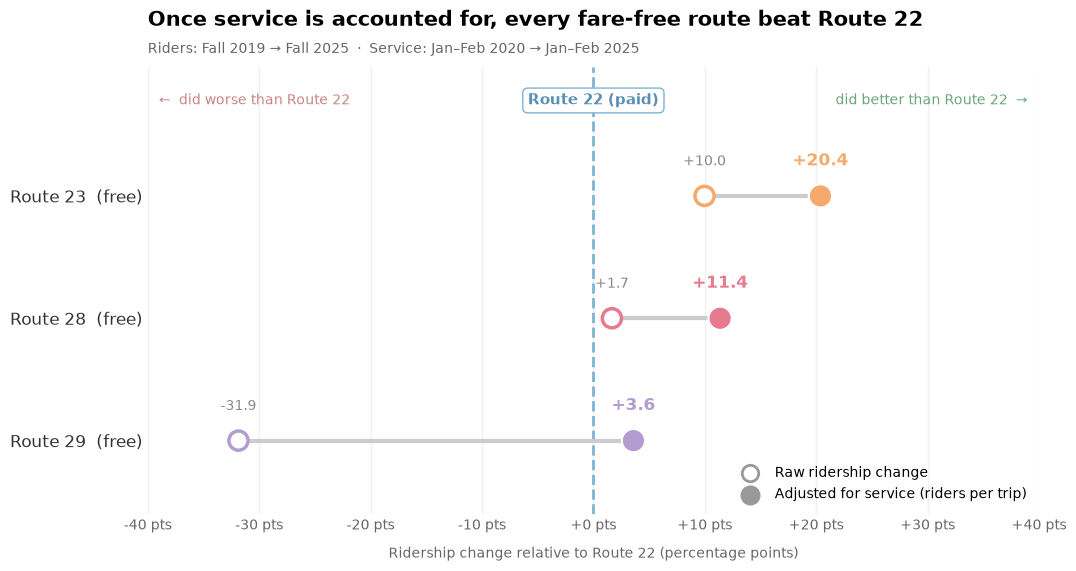

In [6]:
import matplotlib.ticker as mticker

# Gap from Route 22 for the three fare-free routes
raw = riders_pct - riders_pct['22']
adj = per_trip_pct - per_trip_pct['22']

fig, ax = plt.subplots(figsize=(11.5, 5.8))

# ---- Light vertical guides ----
ax.grid(axis='x', color='#F0F0F0', linewidth=1)
ax.set_axisbelow(True)

# ---- Route 22 reference line ----
ax.axvline(0, color=colors['22'], linewidth=2, linestyle='--', zorder=1)
ax.text(0, 2.78, 'Route 22 (paid)', ha='center', va='center', fontsize=10.5, fontweight='bold', color='#5A8FB3',
        bbox=dict(boxstyle='round,pad=0.35', facecolor='white', edgecolor=colors['22']))
ax.text(-39, 2.78, '←  did worse than Route 22', ha='left', va='center', fontsize=10, color='#C98585')
ax.text(39, 2.78, 'did better than Route 22  →', ha='right', va='center', fontsize=10, color='#6AA67A')

# ---- Simple line from raw to adjusted ----
ax.hlines([2, 1, 0], [raw['23'], raw['28'], raw['29']], [adj['23'], adj['28'], adj['29']],
          color='#CCCCCC', linewidth=3, zorder=2)

# ---- Dots: hollow = raw, filled = adjusted ----
ax.scatter([raw['23'], raw['28'], raw['29']], [2, 1, 0], s=190, facecolor='white',
           edgecolor=[colors['23'], colors['28'], colors['29']], linewidth=2.5, zorder=3)
ax.scatter([adj['23'], adj['28'], adj['29']], [2, 1, 0], s=280,
           color=[colors['23'], colors['28'], colors['29']], edgecolor='white', linewidth=1.5, zorder=4)

# ---- Exact values: raw in grey, adjusted bold in the route colour ----
ax.text(raw['23'], 2.25, f"{raw['23']:+.1f}", ha='center', fontsize=10, color='#888888')
ax.text(adj['23'], 2.25, f"{adj['23']:+.1f}", ha='center', fontsize=12.5, fontweight='bold', color=colors['23'])
ax.text(raw['28'], 1.25, f"{raw['28']:+.1f}", ha='center', fontsize=10, color='#888888')
ax.text(adj['28'], 1.25, f"{adj['28']:+.1f}", ha='center', fontsize=12.5, fontweight='bold', color=colors['28'])
ax.text(raw['29'], 0.25, f"{raw['29']:+.1f}", ha='center', fontsize=10, color='#888888')
ax.text(adj['29'], 0.25, f"{adj['29']:+.1f}", ha='center', fontsize=12.5, fontweight='bold', color=colors['29'])

# ---- Legend in neutral grey ----
ax.scatter([], [], s=140, facecolor='white', edgecolor='#999999', linewidth=2, label='Raw ridership change')
ax.scatter([], [], s=180, color='#999999', label='Adjusted for service (riders per trip)')
ax.legend(loc='lower right', frameon=False, fontsize=10)

# ---- Axes ----
ax.set_yticks([2, 1, 0])
ax.set_yticklabels(['Route 23  (free)', 'Route 28  (free)', 'Route 29  (free)'], fontsize=12)
ax.set_xlim(-40, 40)
ax.set_ylim(-0.6, 3.05)
ax.xaxis.set_major_formatter(mticker.FormatStrFormatter('%+d pts'))
ax.set_xlabel('Ridership change relative to Route 22 (percentage points)', color='#666666', labelpad=10)
ax.spines[['top', 'right', 'left', 'bottom']].set_visible(False)
ax.tick_params(length=0, colors='#666666')
ax.tick_params(axis='y', colors='#333333')

ax.set_title('Once service is accounted for, every fare-free route beat Route 22',
             fontsize=15, fontweight='bold', loc='left', pad=30)
fig.text(0.125, 0.905, 'Riders: Fall 2019 → Fall 2025  ·  Service: Jan–Feb 2020 → Jan–Feb 2025',
         fontsize=10, color='#666666')

plt.show()

**Takeaway:** On raw numbers, Routes 23 and 28 did better than Route 22 (+10.0 and +1.7 points) and Route 29 did much worse (−31.9). But Route 22 gained service while the fare-free routes lost it. Once ridership is measured relative to service, all three fare-free routes outperformed Route 22: Route 23 by 20.4 points, Route 28 by 11.4 and Route 29 by 3.6. Route 29's large raw loss came from service cuts, not the fare change.

*Caveat:* the adjustment assumes riders change one-for-one with service. In practice ridership usually falls less than service, so the adjusted gaps are an upper estimate; the true effect lies between the raw and adjusted values.

### B5. Change in riders per bus trip since 2021

How full are the buses? For each group, total weekday riders are divided by total weekday trips run, each Fall, and shown as a percentage change from Fall 2021.
The three fare-free routes are combined (weighted by size), and compared with Route 22, which kept its fare.

$$\text{Riders per trip} = \frac{\text{average weekday riders}}{\text{weekday trips run per day}}$$

**CAGR** (compound annual growth rate) is the steady yearly growth that takes each group from its 2021 value to its 2025 value:

$$\text{CAGR} = \left(\frac{\text{riders per trip}_{2025}}{\text{riders per trip}_{2021}}\right)^{1/4} - 1$$

*Note:* Route 28 was already fare-free in Fall 2021, so the fare-free starting point already includes part of its effect. Trip counts only include trips with a recorded start and end, so absolute riders-per-trip figures run slightly high; this affects both groups equally.

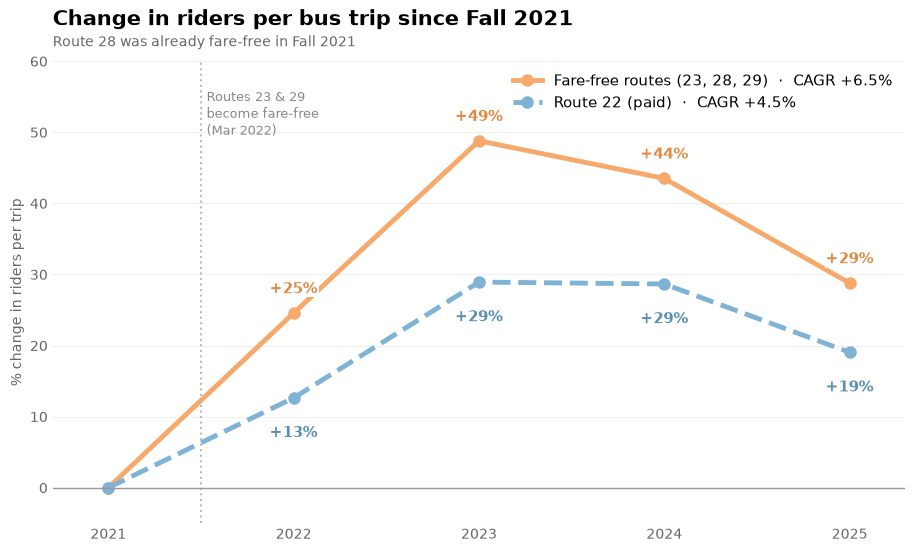

,Change 2021→2025 (%),CAGR (%)
Fare-free (combined),28.8,6.5
Route 22,19.0,4.5


In [7]:
fare_free = ['23', '28', '29']

# Weekday trips per day in Sept-Dec
fall_service = service[(service['day_type'] == 'weekday') & (service['month'].between(9, 12))]
fall_trips = fall_service.pivot_table(index='year', columns='route_id', values='n_trips', aggfunc='sum').loc[2021:2025]
fall_days = pd.Series({year: len(pd.bdate_range(f'{year}-09-01', f'{year}-12-31')) for year in range(2021, 2026)})
trips_per_day = fall_trips.div(fall_days, axis=0)

# Riders per trip: fare-free combined, and Route 22
free_per_trip = riders.loc[2021:2025, fare_free].sum(axis=1) / trips_per_day[fare_free].sum(axis=1)
r22_per_trip  = riders.loc[2021:2025, '22'] / trips_per_day['22']

# % change since 2021, and CAGR
free_pct  = (free_per_trip / free_per_trip[2021] - 1) * 100
r22_pct   = (r22_per_trip  / r22_per_trip[2021]  - 1) * 100
free_cagr = ((free_per_trip[2025] / free_per_trip[2021]) ** (1 / 4) - 1) * 100
r22_cagr  = ((r22_per_trip[2025]  / r22_per_trip[2021])  ** (1 / 4) - 1) * 100

fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(free_pct.index, free_pct, color='#F6A96B', linewidth=3.5, marker='o', markersize=8,
        label=f'Fare-free routes (23, 28, 29)  ·  CAGR {free_cagr:+.1f}%')
ax.plot(r22_pct.index, r22_pct, color=colors['22'], linewidth=3.5, marker='o', markersize=8, linestyle='--',
        label=f'Route 22 (paid)  ·  CAGR {r22_cagr:+.1f}%')

# Fare-free timeline: Routes 23 and 29 joined in March 2022
ax.axvline(2021.5, color='#BBBBBB', linestyle=':', linewidth=1.5)
ax.text(2021.53, 56, 'Routes 23 & 29\nbecome fare-free\n(Mar 2022)', fontsize=9.5, color='#888888', va='top')

# Value at each point (2022-2025): fare-free above, Route 22 below
box = dict(facecolor='white', edgecolor='none', pad=0.6)
[ax.text(x, y + 2.8, f'{y:+.0f}%', ha='center', fontsize=10.5, fontweight='bold', color='#E08A45', bbox=box) for x, y in free_pct.loc[2022:2025].items()]
[ax.text(x, y - 5.5, f'{y:+.0f}%', ha='center', fontsize=10.5, fontweight='bold', color='#5A8FB3', bbox=box) for x, y in r22_pct.loc[2022:2025].items()]

ax.axhline(0, color='#999999', linewidth=1)

ax.set_title('Change in riders per bus trip since Fall 2021', fontsize=15, fontweight='bold', loc='left', pad=26)
fig.text(0.125, 0.905, 'Route 28 was already fare-free in Fall 2021',
         fontsize=10, color='#666666')
ax.set_ylabel('% change in riders per trip', color='#666666')
ax.set_xticks(range(2021, 2026))
ax.set_xlim(2020.7, 2025.3)
ax.set_ylim(-5, 60)
ax.legend(frameon=False, loc='upper right', fontsize=10.5)
ax.grid(axis='y', color='#F0F0F0')
ax.set_axisbelow(True)
ax.spines[['top', 'right', 'left', 'bottom']].set_visible(False)
ax.tick_params(length=0, colors='#666666')

plt.show()

pd.DataFrame({'Change 2021→2025 (%)': [free_pct[2025], r22_pct[2025]], 'CAGR (%)': [free_cagr, r22_cagr]},
             index=['Fare-free (combined)', 'Route 22']).round(1)

**Takeaway:** Buses on the fare-free routes filled up faster than on Route 22 throughout 2022–2025. By 2025, fare-free buses carried 28.8% more riders per trip than in 2021, compared with 19.0% on Route 22 (CAGR 6.5% vs 4.5%).

## 2. Ridership: All Routes

How did the fare-free routes compare with the rest of the MBTA bus network?
Comparison groups:
- **Top 8 routes:** the 8 busiest other routes in 2019 (1, 66, 39, 57, 111, 32, 22, 9)
- **All other routes:** every remaining bus route
Silver Line routes are excluded (bus rapid transit, with different ridership drivers).

### C1. Fare-free routes vs. the rest of the network

Total weekday riders in each group, as a percentage change from Fall 2019.

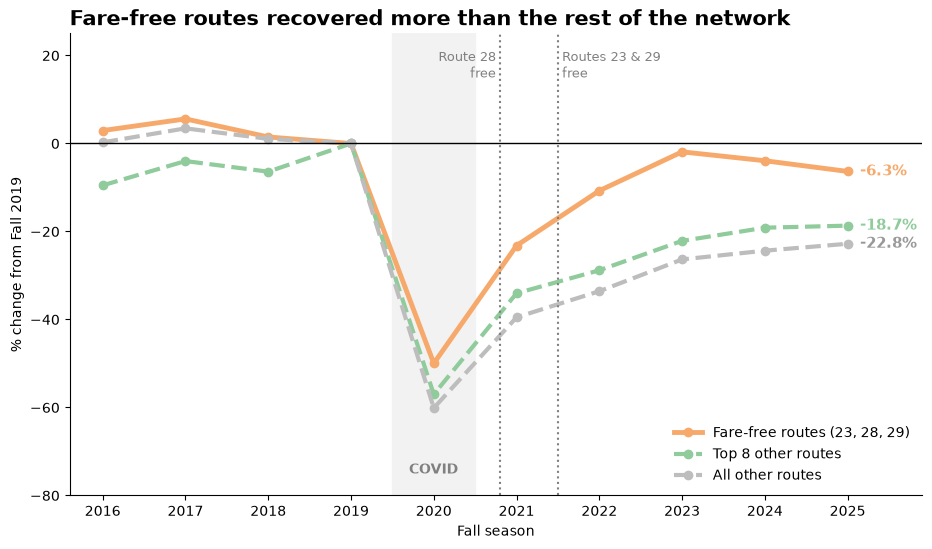

In [8]:
fare_free   = ['23', '28', '29']
top8        = ['1', '66', '39', '57', '111', '32', '22', '9']
silver_line = ['741', '742', '743', '746', '749', '751']

# Weekday riders, without the Silver Line
network = weekday[weekday['route_id'].isin(silver_line) == False]

# Total weekday riders per year in each group
free_total = network[network['route_id'].isin(fare_free)].groupby('year')['avg_daily_boardings'].sum()
top8_total = network[network['route_id'].isin(top8)].groupby('year')['avg_daily_boardings'].sum()
rest_total = network[(network['route_id'].isin(fare_free) == False) &
                     (network['route_id'].isin(top8) == False)].groupby('year')['avg_daily_boardings'].sum()

# % change from 2019
free_pct = (free_total / free_total[2019] - 1) * 100
top8_pct = (top8_total / top8_total[2019] - 1) * 100
rest_pct = (rest_total / rest_total[2019] - 1) * 100

fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(free_pct.index, free_pct, color='#F6A96B', linewidth=3.5, marker='o', label='Fare-free routes (23, 28, 29)')
ax.plot(top8_pct.index, top8_pct, color='#8FCB9B', linewidth=3, marker='o', linestyle='--', label='Top 8 other routes')
ax.plot(rest_pct.index, rest_pct, color='#BDBDBD', linewidth=3, marker='o', linestyle='--', label='All other routes')

# 2025 value at the end of each line
ax.text(2025.15, free_pct[2025], f'{free_pct[2025]:+.1f}%', va='center', fontsize=11, fontweight='bold', color='#F6A96B')
ax.text(2025.15, top8_pct[2025], f'{top8_pct[2025]:+.1f}%', va='center', fontsize=11, fontweight='bold', color='#8FCB9B')
ax.text(2025.15, rest_pct[2025], f'{rest_pct[2025]:+.1f}%', va='center', fontsize=11, fontweight='bold', color='#999999')

ax.axhline(0, color='black', linewidth=1)

# COVID and fare-free dates
ax.axvspan(2019.5, 2020.5, color='#F2F2F2')
ax.text(2020, -75, 'COVID', ha='center', fontsize=10, color='gray', fontweight='bold')
ax.axvline(2020.8, color='gray', linestyle=':')
ax.axvline(2021.5, color='gray', linestyle=':')
ax.text(2020.75, 15, 'Route 28\nfree', ha='right', fontsize=9, color='gray')
ax.text(2021.55, 15, 'Routes 23 & 29\nfree', fontsize=9, color='gray')

ax.set_title('Fare-free routes recovered more than the rest of the network', fontsize=15, fontweight='bold', loc='left')
ax.set_xlabel('Fall season')
ax.set_ylabel('% change from Fall 2019')
ax.set_xticks(range(2016, 2026))
ax.set_xlim(2015.6, 2025.9)
ax.set_ylim(-80, 25)
ax.legend(frameon=False, loc='lower right')
ax.spines[['top', 'right']].set_visible(False)

plt.show()

**Takeaway:** From Fall 2019 to Fall 2025, weekday ridership on the fare-free routes fell 6.3%, compared with 18.7% on the top 8 other routes and 22.8% on all other routes. The fare-free routes recovered far more of their pre-COVID ridership than the rest of the network.

### C2. Fare-free routes' share of all weekday bus riders

Routes 23, 28 and 29 as a percentage of all weekday MBTA bus riders (Silver Line excluded).
A rising share means these routes grew faster, or shrank more slowly, than the network as a whole.

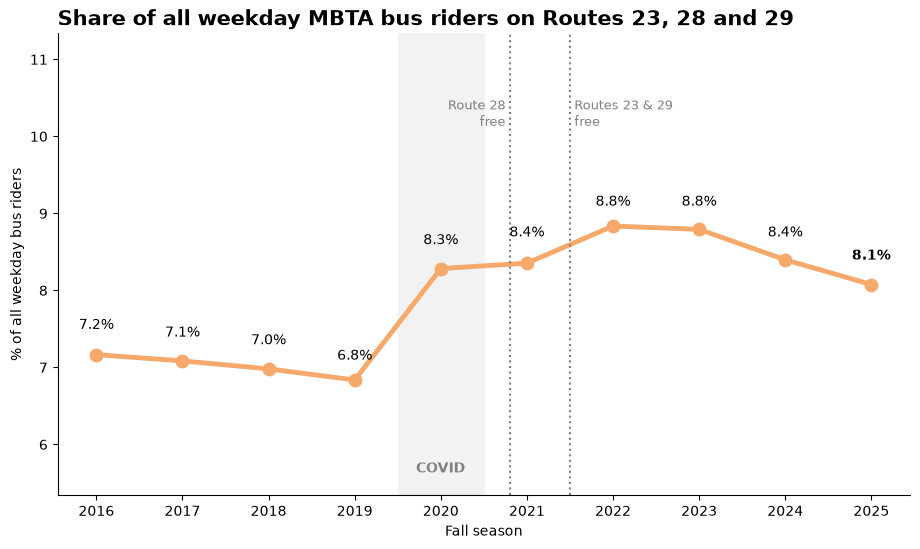

In [9]:
# All weekday riders per year, and the fare-free routes' share
all_total = network.groupby('year')['avg_daily_boardings'].sum()
share = free_total / all_total * 100

fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(share.index, share, color='#F6A96B', linewidth=3.5, marker='o', markersize=9)

# Value above each point
for_label = share.round(1)
ax.text(2016, for_label[2016] + 0.3, f'{for_label[2016]}%', ha='center', fontsize=10)
ax.text(2017, for_label[2017] + 0.3, f'{for_label[2017]}%', ha='center', fontsize=10)
ax.text(2018, for_label[2018] + 0.3, f'{for_label[2018]}%', ha='center', fontsize=10)
ax.text(2019, for_label[2019] + 0.3, f'{for_label[2019]}%', ha='center', fontsize=10)
ax.text(2020, for_label[2020] + 0.3, f'{for_label[2020]}%', ha='center', fontsize=10)
ax.text(2021, for_label[2021] + 0.3, f'{for_label[2021]}%', ha='center', fontsize=10)
ax.text(2022, for_label[2022] + 0.3, f'{for_label[2022]}%', ha='center', fontsize=10)
ax.text(2023, for_label[2023] + 0.3, f'{for_label[2023]}%', ha='center', fontsize=10)
ax.text(2024, for_label[2024] + 0.3, f'{for_label[2024]}%', ha='center', fontsize=10)
ax.text(2025, for_label[2025] + 0.3, f'{for_label[2025]}%', ha='center', fontsize=10, fontweight='bold')

# COVID and fare-free dates
ax.axvspan(2019.5, 2020.5, color='#F2F2F2')
ax.text(2020, share.min() - 1.2, 'COVID', ha='center', fontsize=10, color='gray', fontweight='bold')
ax.axvline(2020.8, color='gray', linestyle=':')
ax.axvline(2021.5, color='gray', linestyle=':')
ax.text(2020.75, share.max() + 1.3, 'Route 28\nfree', ha='right', fontsize=9, color='gray')
ax.text(2021.55, share.max() + 1.3, 'Routes 23 & 29\nfree', fontsize=9, color='gray')

ax.set_title('Share of all weekday MBTA bus riders on Routes 23, 28 and 29', fontsize=15, fontweight='bold', loc='left')
ax.set_xlabel('Fall season')
ax.set_ylabel('% of all weekday bus riders')
ax.set_xticks(range(2016, 2026))
ax.set_ylim(share.min() - 1.5, share.max() + 2.5)
ax.spines[['top', 'right']].set_visible(False)

plt.show()

**Takeaway:** The fare-free routes carried 6.8% of all weekday bus riders in 2019 and 8.8% in 2022–2023, before easing to 8.1% in 2025.

*Caveat:* much of the jump happened in 2020 (6.8% → 8.3%), before fares were removed: riders on these routes depend on transit and kept riding through COVID more than riders elsewhere. The rise after 2021 (8.4% → 8.8%) is the part more plausibly linked to free fares.

### C3. Does the result depend on which routes we compare against?

Route 22 is a single route, so we check the result against two larger groups as well: the **8 busiest other routes** and **all other routes**.
Routes 23, 28 and 29 are combined into one fare-free group (total riders and total trips).

**Step 1: Change in riders** for each group, Fall 2019 to Fall 2025:

$$R = \left(\frac{\text{riders}_{2025}}{\text{riders}_{2019}} - 1\right) \times 100$$

**Step 2: Change in service** (weekday trips), January–February 2020 to January–February 2025:

$$S = \left(\frac{\text{trips}_{2025}}{\text{trips}_{2020}} - 1\right) \times 100$$

**Step 3: Change in riders per trip**, i.e. ridership adjusted for service:

$$A = \left(\frac{1 + R/100}{1 + S/100} - 1\right) \times 100$$

For example, if riders fell 7% and service fell 7%, riders per trip did not change (A = 0).

**Step 4: Gap between the fare-free routes and each comparison group:**

$$\text{Raw gap} = R_{\text{fare-free}} - R_{\text{group}} \qquad \text{Adjusted gap} = A_{\text{fare-free}} - A_{\text{group}}$$

A positive gap means the fare-free routes did better than that group. The **hollow dot** is the raw gap; the **filled dot** is the adjusted gap.
If both dots are positive against every group, the result does not depend on choosing Route 22 as the comparison.

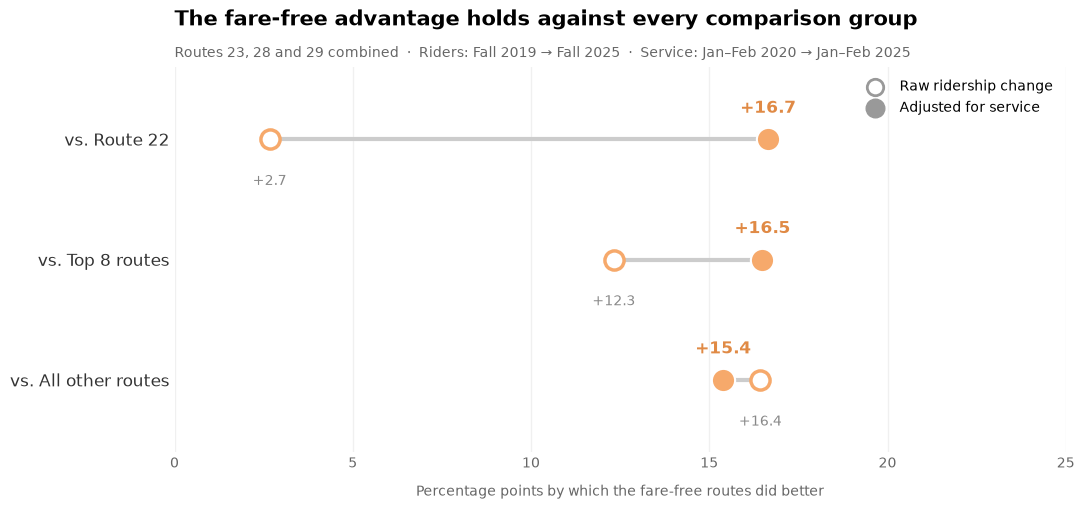

In [10]:

other_routes = network[(network['route_id'].isin(fare_free) == False) &
                       (network['route_id'].isin(top8) == False)]['route_id'].unique()

# Riders: % change 2019 -> 2025 for each group (totals)
riders_free = (free_total[2025] / free_total[2019] - 1) * 100
riders_22   = (riders.loc[2025, '22'] / riders.loc[2019, '22'] - 1) * 100
riders_top8 = (top8_total[2025] / top8_total[2019] - 1) * 100
riders_rest = (rest_total[2025] / rest_total[2019] - 1) * 100

# Service: % change in weekday trips, Jan-Feb 2020 -> Jan-Feb 2025 (totals)
service_free = (trips_2025.reindex(fare_free).sum() / trips_2020.reindex(fare_free).sum() - 1) * 100
service_22   = (trips_2025['22'] / trips_2020['22'] - 1) * 100
service_top8 = (trips_2025.reindex(top8).sum() / trips_2020.reindex(top8).sum() - 1) * 100
service_rest = (trips_2025.reindex(other_routes).sum() / trips_2020.reindex(other_routes).sum() - 1) * 100

# Riders per trip (adjusted for service)
adj_free = ((1 + riders_free / 100) / (1 + service_free / 100) - 1) * 100
adj_22   = ((1 + riders_22 / 100)   / (1 + service_22 / 100) - 1) * 100
adj_top8 = ((1 + riders_top8 / 100) / (1 + service_top8 / 100) - 1) * 100
adj_rest = ((1 + riders_rest / 100) / (1 + service_rest / 100) - 1) * 100

# Gap: fare-free minus each comparison group
raw_vals = [riders_free - riders_22, riders_free - riders_top8, riders_free - riders_rest]
adj_vals = [adj_free - adj_22,       adj_free - adj_top8,       adj_free - adj_rest]
fig, ax = plt.subplots(figsize=(11.5, 5))

ax.grid(axis='x', color='#F0F0F0', linewidth=1)
ax.set_axisbelow(True)

# Line from raw to adjusted, then the two dots
ax.hlines([2, 1, 0], raw_vals, adj_vals, color='#CCCCCC', linewidth=3, zorder=2)
ax.scatter(raw_vals, [2, 1, 0], s=190, facecolor='white', edgecolor='#F6A96B', linewidth=2.5, zorder=3)
ax.scatter(adj_vals, [2, 1, 0], s=280, color='#F6A96B', edgecolor='white', linewidth=1.5, zorder=4)

# Raw value below the dot, adjusted value above (so they never overlap)
ax.text(raw_vals[0], 1.62, f'{raw_vals[0]:+.1f}', ha='center', fontsize=10, color='#888888')
ax.text(adj_vals[0], 2.22, f'{adj_vals[0]:+.1f}', ha='center', fontsize=12.5, fontweight='bold', color='#E08A45')
ax.text(raw_vals[1], 0.62, f'{raw_vals[1]:+.1f}', ha='center', fontsize=10, color='#888888')
ax.text(adj_vals[1], 1.22, f'{adj_vals[1]:+.1f}', ha='center', fontsize=12.5, fontweight='bold', color='#E08A45')
ax.text(raw_vals[2], -0.38, f'{raw_vals[2]:+.1f}', ha='center', fontsize=10, color='#888888')
ax.text(adj_vals[2], 0.22, f'{adj_vals[2]:+.1f}', ha='center', fontsize=12.5, fontweight='bold', color='#E08A45')

# Legend in neutral grey
ax.scatter([], [], s=140, facecolor='white', edgecolor='#999999', linewidth=2, label='Raw ridership change')
ax.scatter([], [], s=180, color='#999999', label='Adjusted for service')
ax.legend(loc='upper right', frameon=False, fontsize=10)

ax.set_yticks([2, 1, 0])
ax.set_yticklabels(['vs. Route 22', 'vs. Top 8 routes', 'vs. All other routes'], fontsize=12)
ax.set_xlim(0, 25)
ax.set_ylim(-0.6, 2.6)
ax.set_xlabel('Percentage points by which the fare-free routes did better', color='#666666', labelpad=10)
ax.spines[['top', 'right', 'left', 'bottom']].set_visible(False)
ax.tick_params(length=0, colors='#666666')
ax.tick_params(axis='y', colors='#333333')

ax.set_title('The fare-free advantage holds against every comparison group',
             fontsize=15, fontweight='bold', loc='left', pad=30)
fig.text(0.125, 0.90, 'Routes 23, 28 and 29 combined  ·  Riders: Fall 2019 → Fall 2025  ·  Service: Jan–Feb 2020 → Jan–Feb 2025',
         fontsize=10, color='#666666')

plt.show()

**Takeaway:** The fare-free routes outperformed every comparison group, by 2.7 to 16.4 points on raw ridership and by 15.4 to 16.7 points after adjusting for service. The adjusted gaps are remarkably consistent, whether the comparison is Route 22, the 8 busiest routes or the whole network, so the result does not depend on the choice of comparison route.

### C4. Riders beyond each route's share of service

For each route: its share of all weekday bus riders minus its share of all weekday trips run, each Fall (Silver Line excluded).

$$\text{Gap} = \text{share of riders} - \text{share of trips}$$

Above 0 means the route carries more riders than its share of buses would suggest. A gap that grows after the routes became fare-free means they attracted riders faster than their service grew.

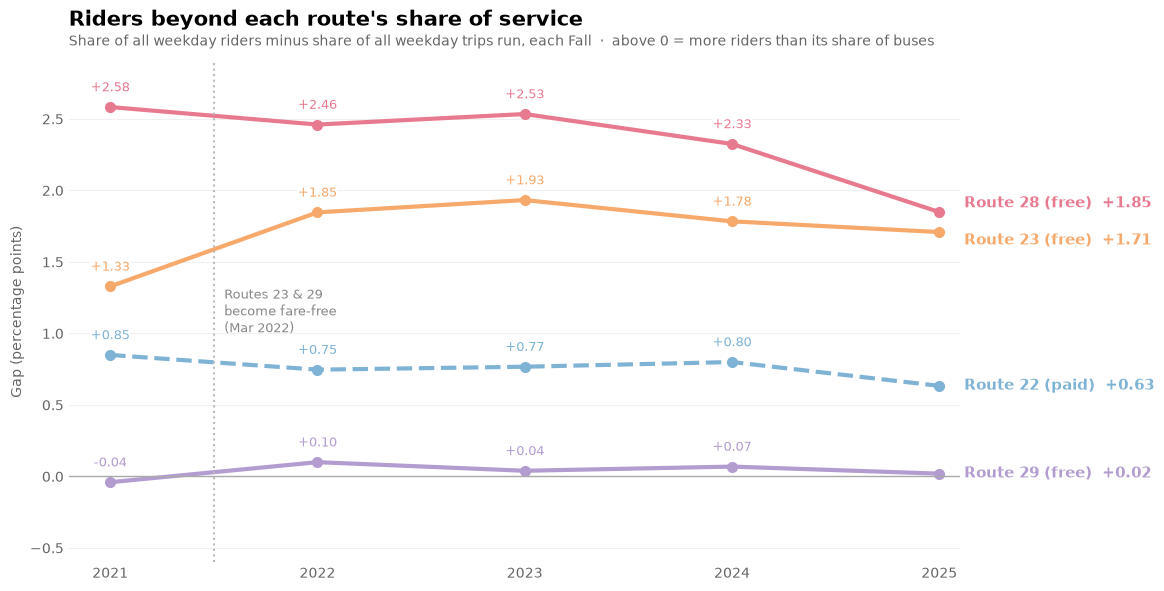

In [11]:
# Sept-Dec weekday trips, every route in the network (no Silver Line)
network_routes = network['route_id'].unique()
fall_all = service[(service['day_type'] == 'weekday') & (service['month'].between(9, 12)) &
                   (service['route_id'].isin(network_routes))]

# Network totals per year
trips_all  = fall_all.groupby('year')['n_trips'].sum()
riders_all = network.groupby('year')['avg_daily_boardings'].sum()

# Each route's share of riders and share of trips, 2021-2025
trips_by_route = fall_all.pivot_table(index='year', columns='route_id', values='n_trips', aggfunc='sum')
rider_share = (riders.div(riders_all, axis=0) * 100).loc[2021:2025]
trip_share  = (trips_by_route.div(trips_all, axis=0) * 100).loc[2021:2025]

# Gap in percentage points: share of riders minus share of trips
gap = rider_share - trip_share

fig, ax = plt.subplots(figsize=(11.5, 6.5))

ax.plot(gap.index, gap['28'], color=colors['28'], linewidth=3, marker='o', markersize=7)
ax.plot(gap.index, gap['23'], color=colors['23'], linewidth=3, marker='o', markersize=7)
ax.plot(gap.index, gap['22'], color=colors['22'], linewidth=3, marker='o', markersize=7, linestyle='--')
ax.plot(gap.index, gap['29'], color=colors['29'], linewidth=3, marker='o', markersize=7)

# Value above each point, 2021-2024 (white background so lines don't cross the numbers)
box = dict(facecolor='white', edgecolor='none', pad=0.5)
[ax.text(x, y + 0.11, f'{y:+.2f}', ha='center', fontsize=9, color=colors['28'], bbox=box) for x, y in gap.loc[2021:2024, '28'].items()]
[ax.text(x, y + 0.11, f'{y:+.2f}', ha='center', fontsize=9, color=colors['23'], bbox=box) for x, y in gap.loc[2021:2024, '23'].items()]
[ax.text(x, y + 0.11, f'{y:+.2f}', ha='center', fontsize=9, color=colors['22'], bbox=box) for x, y in gap.loc[2021:2024, '22'].items()]
[ax.text(x, y + 0.11, f'{y:+.2f}', ha='center', fontsize=9, color=colors['29'], bbox=box) for x, y in gap.loc[2021:2024, '29'].items()]

# Route name and 2025 value at the end of each line
ax.text(2025.12, gap.loc[2025, '28'] + 0.06, f"Route 28 (free)  {gap.loc[2025, '28']:+.2f}", va='center', fontsize=10.5, fontweight='bold', color=colors['28'])
ax.text(2025.12, gap.loc[2025, '23'] - 0.06, f"Route 23 (free)  {gap.loc[2025, '23']:+.2f}", va='center', fontsize=10.5, fontweight='bold', color=colors['23'])
ax.text(2025.12, gap.loc[2025, '22'],        f"Route 22 (paid)  {gap.loc[2025, '22']:+.2f}", va='center', fontsize=10.5, fontweight='bold', color=colors['22'])
ax.text(2025.12, gap.loc[2025, '29'],        f"Route 29 (free)  {gap.loc[2025, '29']:+.2f}", va='center', fontsize=10.5, fontweight='bold', color=colors['29'])

# Zero line: riders exactly in line with share of service
ax.axhline(0, color='#AAAAAA', linewidth=1)

# Fare-free timeline (label in empty space)
ax.axvline(2021.5, color='#BBBBBB', linestyle=':', linewidth=1.5)
ax.text(2021.55, 1.15, 'Routes 23 & 29\nbecome fare-free\n(Mar 2022)', fontsize=9.5, color='#888888', va='center')

ax.set_title("Riders beyond each route's share of service", fontsize=15, fontweight='bold', loc='left', pad=26)
fig.text(0.125, 0.905, 'Share of all weekday riders minus share of all weekday trips run, each Fall  ·  above 0 = more riders than its share of buses',
         fontsize=10, color='#666666')
ax.set_ylabel('Gap (percentage points)', color='#666666')
ax.set_xticks(range(2021, 2026))
ax.set_xlim(2020.8, 2025.1)
ax.set_ylim(-0.6, 2.9)                       # room below zero so Route 29 is clearly visible
ax.grid(axis='y', color='#F0F0F0')
ax.set_axisbelow(True)
ax.spines[['top', 'right', 'left', 'bottom']].set_visible(False)
ax.tick_params(length=0, colors='#666666')

plt.show()

**Takeaway:** Route 23's gap jumped when it became fare-free (+1.33 points in 2021 to +1.85 in 2022) and stayed above its pre-program level, while Route 22's gap stayed flat at around +0.6 to +0.85. Route 28, already fare-free in 2021, carries the most riders relative to its service of the four routes, though its gap narrowed in 2025 with that year's ridership dip. Route 29 carries roughly its share of riders for its share of buses (gap close to zero).

## 3. Walking Areas

### A7. Who lives within walking distance of each route

Outlines show everything within a quarter mile (about a 5-minute walk) of each route's stops, over median household income by census tract.
The three fare-free routes and Route 22 serve overlapping, lower-income neighbourhoods, which is why Route 22 is a fair comparison.

C:\Users\sahil\AppData\Local\Temp\ipykernel_15544\544660322.py:8: DtypeWarning: Columns (0: shape_id) have mixed types. Specify dtype option on import or set low_memory=False.
  shapes = pd.read_csv(processed + r'\route_shapes.csv', dtype={'route_id': str})


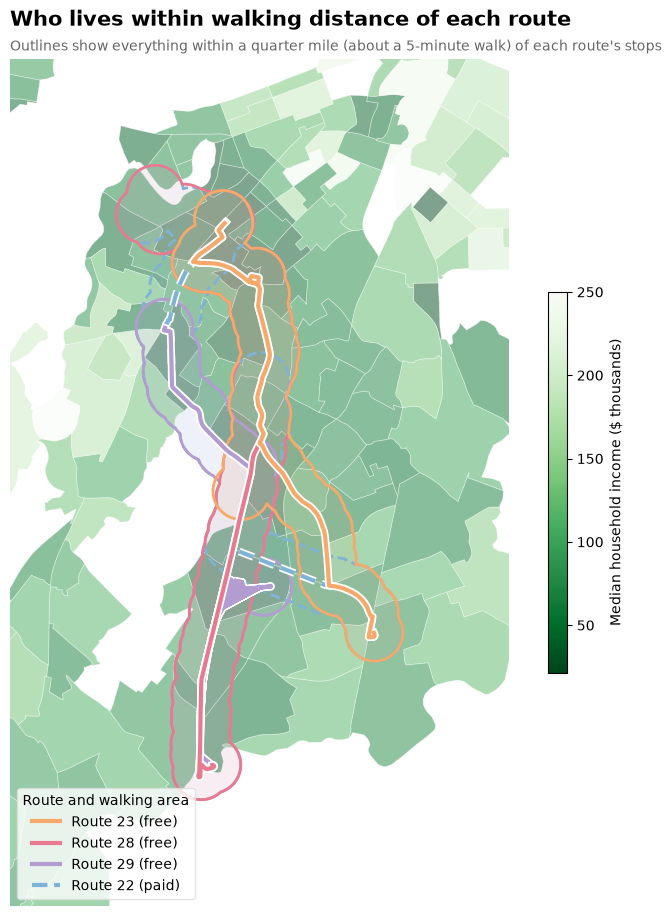

In [12]:
import geopandas as gpd
import matplotlib.patheffects as pe
from matplotlib.lines import Line2D

# ---- Load ----
tracts = gpd.read_file(processed + r'\boston_tracts_2024.geojson').to_crs('EPSG:26986')
stops  = pd.read_csv(processed + r'\route_stops.csv', dtype={'route_id': str})
shapes = pd.read_csv(processed + r'\route_shapes.csv', dtype={'route_id': str})

# ---- Walking areas: a quarter-mile circle around every stop, merged per route ----
stops = stops[stops['route_id'].isin(['23', '28', '29', '22'])]
stops = gpd.GeoDataFrame(stops, geometry=gpd.points_from_xy(stops['stop_lon'], stops['stop_lat']),
                         crs='EPSG:4326').to_crs('EPSG:26986')          # meters, so distances work
stops['geometry'] = stops.buffer(402)                                   # 402 m = a quarter mile
areas = stops.dissolve(by='route_id')                                   # one shape per route

# ---- Route lines (one direction, points in order) ----
shapes = shapes[shapes['route_id'].isin(['23', '28', '29', '22']) & (shapes['direction_id'] == 0)]
shapes = shapes.sort_values(['route_id', 'shape_pt_sequence'])
shapes = gpd.GeoDataFrame(shapes, geometry=gpd.points_from_xy(shapes['shape_pt_lon'], shapes['shape_pt_lat']),
                          crs='EPSG:4326').to_crs('EPSG:26986')
s23 = shapes[shapes['route_id'] == '23']
s28 = shapes[shapes['route_id'] == '28']
s29 = shapes[shapes['route_id'] == '29']
s22 = shapes[shapes['route_id'] == '22']

tracts['income_k'] = tracts['median_hh_income'] / 1000          # $ thousands, for a cleaner legend

fig, ax = plt.subplots(figsize=(10, 11))

# Tracts: soft green, darker = lower income
tracts.plot(ax=ax, column='income_k', cmap='Greens_r', edgecolor='white', linewidth=0.5, alpha=0.5,
            legend=True, legend_kwds={'label': 'Median household income ($ thousands)', 'shrink': 0.45})

# Walking areas: faint fill + coloured outline
areas.loc[['22']].plot(ax=ax, facecolor=colors['22'], alpha=0.08)
areas.loc[['29']].plot(ax=ax, facecolor=colors['29'], alpha=0.08)
areas.loc[['28']].plot(ax=ax, facecolor=colors['28'], alpha=0.08)
areas.loc[['23']].plot(ax=ax, facecolor=colors['23'], alpha=0.08)
areas.loc[['22']].boundary.plot(ax=ax, color=colors['22'], linewidth=2, linestyle='--')
areas.loc[['29']].boundary.plot(ax=ax, color=colors['29'], linewidth=2)
areas.loc[['28']].boundary.plot(ax=ax, color=colors['28'], linewidth=2)
areas.loc[['23']].boundary.plot(ax=ax, color=colors['23'], linewidth=2)

# Route lines on top, with a white edge so they stand out
halo = [pe.Stroke(linewidth=5.5, foreground='white'), pe.Normal()]
ax.plot(s22.geometry.x, s22.geometry.y, color=colors['22'], linewidth=3, linestyle='--', path_effects=halo)
ax.plot(s29.geometry.x, s29.geometry.y, color=colors['29'], linewidth=3, path_effects=halo)
ax.plot(s28.geometry.x, s28.geometry.y, color=colors['28'], linewidth=3, path_effects=halo)
ax.plot(s23.geometry.x, s23.geometry.y, color=colors['23'], linewidth=3, path_effects=halo)

# Zoom to the four routes
xmin, ymin, xmax, ymax = areas.total_bounds
ax.set_xlim(xmin - 1500, xmax + 1500)
ax.set_ylim(ymin - 1500, ymax + 1500)
ax.set_axis_off()

ax.legend(handles=[Line2D([0], [0], color=colors['23'], linewidth=3, label='Route 23 (free)'),
                   Line2D([0], [0], color=colors['28'], linewidth=3, label='Route 28 (free)'),
                   Line2D([0], [0], color=colors['29'], linewidth=3, label='Route 29 (free)'),
                   Line2D([0], [0], color=colors['22'], linewidth=3, linestyle='--', label='Route 22 (paid)')],
          title='Route and walking area', loc='lower left', frameon=True,
          facecolor='white', edgecolor='#DDDDDD', fontsize=10, title_fontsize=10)

ax.set_title('Who lives within walking distance of each route', fontsize=15, fontweight='bold', loc='left', pad=24)
ax.text(0, 1.01, "Outlines show everything within a quarter mile (about a 5-minute walk) of each route's stops",
        transform=ax.transAxes, fontsize=10, color='#666666')

plt.show()